# Foundations 7: Complex numbers

*Learning path: foundations, part 7 of 10.* [Index](README.md) · Previous: [Trigonometry](06-trigonometry.ipynb) · Next: [Calculus](08-calculus.ipynb)

The equation $x^2 = -1$ has no real solution, because squares are never negative. Mathematicians invented a number
that solves it anyway, $i$, and discovered that the new numbers explain rotations, waves and electrical circuits better
than the old ones. You will learn

* how to compute with $i$: adding, multiplying, dividing,
* the **complex plane**, where complex numbers are points,
* modulus, argument and the **polar form**,
* why multiplying means *rotating and stretching*,
* **Euler's formula** $e^{i\theta} = \cos\theta + i\sin\theta$,
* the $n$-th **roots of unity**, and a first look at the Mandelbrot set.

## 1. The imaginary unit

Galileo knows $i$ (also written `j`, as engineers do) with $i^2 = -1$. Square roots of negative numbers become
multiples of $i$:

In [1]:
i^2
sqrt(-9)
i^3
i^4

-1

3*i

> `sqrt`: Square root; sqrt(-1) is the imaginary unit i.

-i

1

The powers of $i$ repeat with period 4: $i, -1, -i, 1, i, \ldots$

A **complex number** is $z = a + bi$ with real numbers $a$ (the **real part**) and $b$ (the **imaginary part**).
Computing with them follows the usual rules of algebra plus $i^2 = -1$:

In [2]:
z = 3 + 4*i;
w = 1 - 2*i;
z + w
z - w
z*w

4+2*i

2+6*i

11-2*i

By hand: $(3 + 4i)(1 - 2i) = 3 - 6i + 4i - 8i^2 = 3 - 2i + 8 = 11 - 2i$.

### The conjugate and division

The **conjugate** of $z = a + bi$ is $\bar z = a - bi$. A number times its conjugate is always real:
$z\bar z = a^2 + b^2$. That is the trick for dividing: multiply top and bottom by the conjugate of the bottom.

In [3]:
conj(z)
z*conj(z)
z/w

3-4*i

> `conj` (see `real`): Real part, imaginary part, complex conjugate, modulus |z| and argument (angle) of z.

25

-1+2*i

By hand: $\dfrac{3 + 4i}{1 - 2i} = \dfrac{(3 + 4i)(1 + 2i)}{(1 - 2i)(1 + 2i)} = \dfrac{-5 + 10i}{5} = -1 + 2i$.
`real(z)` and `imag(z)` pick out the two parts; letters are treated as real numbers:

In [4]:
real(z/w)
imag(z/w)
real(1/(a + b*i))
imag(1/(a + b*i))

-1

> `real`: Real part, imaginary part, complex conjugate, modulus |z| and argument (angle) of z.

2

> `imag` (see `real`): Real part, imaginary part, complex conjugate, modulus |z| and argument (angle) of z.

a/(a^2+b^2)

> `real`: Real part, imaginary part, complex conjugate, modulus |z| and argument (angle) of z.

-b/(a^2+b^2)

> `imag` (see `real`): Real part, imaginary part, complex conjugate, modulus |z| and argument (angle) of z.

## 2. The complex plane

A complex number $a + bi$ is a point $(a, b)$ in the plane: the real part across, the imaginary part up. Adding two
complex numbers adds the coordinates, which is the same as adding arrows (vectors) head to tail.

To draw points we use `scatter(data, [re im])`: `data` has one row per point, here `[real part, imaginary part]`,
and `[re im]` names the two columns (the first is drawn across, the second up). The lines from the origin are drawn
with `parametric(X, Y, s, 0, 1)`, the points $(sX, sY)$ for $s$ from 0 to 1.

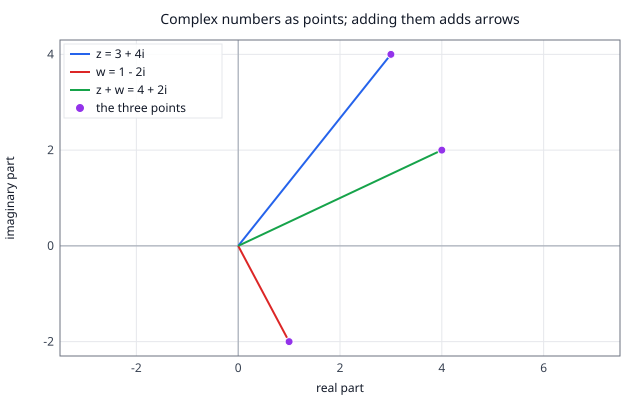

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [5]:
pts = [3 4; 1 -2; 4 2];
arrows = show(parametric(3*s, 4*s, s, 0, 1), parametric(s, -2*s, s, 0, 1), parametric(4*s, 2*s, s, 0, 1));
p = show(arrows, scatter(pts, [re im]));
p = legend(p, "z = 3 + 4i", "w = 1 - 2i", "z + w = 4 + 2i", "the three points");
labels(title(p, "Complex numbers as points; adding them adds arrows"), "real part", "imaginary part")

The horizontal axis is the real part and the vertical axis the imaginary part. The arrow to $z + w$ is the diagonal
of the parallelogram spanned by the arrows to $z$ and $w$.

## 3. Modulus, argument and polar form

The distance from 0 to $z$ is the **modulus** $|z| = \sqrt{a^2 + b^2}$; the angle of the arrow, measured from the
positive real axis, is the **argument** $\arg z$. With $r = |z|$ and $\varphi = \arg z$ (trigonometry of the unit
circle, scaled by $r$):

$$z = r(\cos\varphi + i\sin\varphi).$$

`abs(z)` and `arg(z)` compute them; `polar(z)` gives both as `[r, phi]`:

In [6]:
abs(3 + 4*i)
arg(1 + i)
polar(-1 + sqrt(3)*i)
polar(3 + 4*i)

5

> `abs`: Absolute value; for a complex number a + b*i the modulus sqrt(a^2 + b^2).

pi/4

> `arg` (see `real`): Real part, imaginary part, complex conjugate, modulus |z| and argument (angle) of z.

[2, 2*pi/3]

> `polar` (see `rect`): rect writes z as a + b*i; polar gives [r, phi] with z = r*exp(i*phi).

[5, 0.9272952180016122]

> `polar` (see `rect`): rect writes z as a + b*i; polar gives [r, phi] with z = r*exp(i*phi).

$-1 + \sqrt3\,i$ has modulus 2 and argument $2\pi/3 = 120^\circ$. The argument of $3 + 4i$ is not a famous angle, so it
comes out as a decimal (in radians).

### Multiplying rotates and stretches

The polar form makes multiplication easy: **moduli multiply and arguments add**.

$$r_1 e^{i\varphi_1} \cdot r_2 e^{i\varphi_2} = r_1 r_2\, e^{i(\varphi_1 + \varphi_2)}.$$

So multiplying by $i$ (modulus 1, argument $90^\circ$) rotates a quarter turn, and multiplying by $1 + i$ (modulus
$\sqrt2$, argument $45^\circ$) rotates by $45^\circ$ and stretches by $\sqrt2$. Repeated multiplication by
$z = 0.9 + 0.3i$ (modulus about 0.95, argument about $18^\circ$) walks along a spiral into the origin. The table has
one row per power $z^k$, $k = 0, \ldots, 40$: its real and imaginary parts.

3*sqrt(10)/10

> `abs`: Absolute value; for a complex number a + b*i the modulus sqrt(a^2 + b^2).

0.3217505543966422

> `arg` (see `real`): Real part, imaginary part, complex conjugate, modulus |z| and argument (angle) of z.

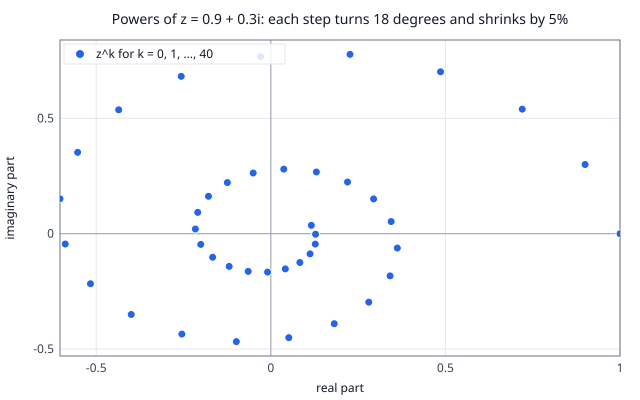

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [7]:
z = 0.9 + 0.3*i;
abs(z)
arg(z)
P = table([real(z^k), imag(z^k)], k, 0, 40);
p = legend(scatter(P, [re im]), "z^k for k = 0, 1, ..., 40");
labels(title(p, "Powers of z = 0.9 + 0.3i: each step turns 18 degrees and shrinks by 5%"), "real part", "imaginary part")

The first point is $z^0 = 1$ on the right; each next point is turned about $18^\circ$ counter-clockwise and is about
5% closer to 0.

## 4. Euler's formula

In 1748 Euler found the formula that connects the exponential function with trigonometry:

$$e^{i\theta} = \cos\theta + i\sin\theta.$$

So $e^{i\theta}$ is the point at angle $\theta$ on the unit circle, and every complex number is $z = re^{i\varphi}$.
`rect(z)` writes a number in the form $a + bi$:

In [8]:
rect(exp(i*x))
exp(i*pi/3)
exp(i*pi)

cos(x)+i*sin(x)

> `rect`: rect writes z as a + b*i; polar gives [r, phi] with z = r*exp(i*phi).

1/2+sqrt(3)*i/2

> `exp`: Exponential function.

-1

> `exp`: Exponential function.

The last line is **Euler's identity** $e^{i\pi} = -1$, or $e^{i\pi} + 1 = 0$, connecting the five most important
constants of mathematics.

Euler's formula turns trigonometry into algebra. Since $e^{ix}e^{iy} = e^{i(x+y)}$, the real and imaginary parts of the
product give the addition formulas of the previous lesson:

In [9]:
rect(exp(i*x)*exp(i*y))
rect((cos(x) + i*sin(x))*(cos(y) + i*sin(y)))

cos(x+y)+i*sin(x+y)

> `rect`: rect writes z as a + b*i; polar gives [r, phi] with z = r*exp(i*phi).

-sin(x)*sin(y)+cos(x)*cos(y)+i*(sin(x)*cos(y)+cos(x)*sin(y))

> `rect`: rect writes z as a + b*i; polar gives [r, phi] with z = r*exp(i*phi).

Comparing the two lines: $\cos(x+y) = \cos x\cos y - \sin x \sin y$ and $\sin(x+y) = \sin x\cos y + \cos x\sin y$.
Likewise $(\cos x + i\sin x)^n = \cos nx + i\sin nx$ (**de Moivre's formula**); for $n = 2$:

In [10]:
real((cos(x) + i*sin(x))^2)
imag((cos(x) + i*sin(x))^2)

1-2*sin(x)^2

> `real`: Real part, imaginary part, complex conjugate, modulus |z| and argument (angle) of z.

2*sin(x)*cos(x)

> `imag` (see `real`): Real part, imaginary part, complex conjugate, modulus |z| and argument (angle) of z.

These are $\cos 2x$ and $\sin 2x$. Powers of complex numbers are easy in polar form too: $(1 + i)^{10}$ has modulus
$\sqrt2^{10} = 32$ and argument $10 \cdot 45^\circ = 450^\circ = 90^\circ$, so it is $32i$:

In [11]:
(1 + i)^10

32*i

## 5. Roots of unity

The equation $z^n = 1$ has $n$ solutions, the **$n$-th roots of unity** $e^{2\pi i k/n}$, $k = 0, 1, \ldots, n-1$. They
are the corners of a regular $n$-gon on the unit circle. For $n = 6$, exactly:

In [12]:
table(exp(2*pi*i*k/6), k, 0, 5)

[1, 1/2+sqrt(3)*i/2, -1/2+sqrt(3)*i/2, -1, -1/2-sqrt(3)*i/2, 1/2-sqrt(3)*i/2]

> `table`: A row with expr for each k; when expr is itself a row, the rows stack into a matrix.

Drawn with the unit circle (12 roots this time; the table has one row `[real part, imaginary part]` per root):

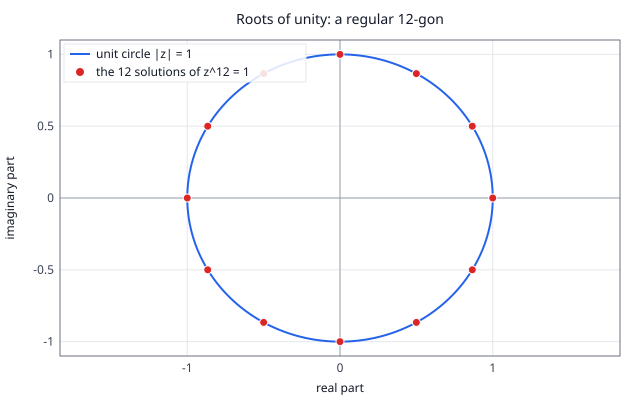

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [13]:
R = table([cos(2*pi*k/12), sin(2*pi*k/12)], k, 0, 11);
p = show(parametric(cos(t), sin(t), t, 0, 2*pi), scatter(R, [re im]));
p = legend(p, "unit circle |z| = 1", "the 12 solutions of z^12 = 1");
labels(title(p, "Roots of unity: a regular 12-gon"), "real part", "imaginary part")

`solve` finds roots of other polynomials. The four roots of $z^4 + 4 = 0$ are $\pm1 \pm i$, the corners of a square:

In [14]:
solve(z^4 + 4 == 0, z)

[1-i, 1+i, -1-i, -1+i]

> `z^4+4` = 0 has no rational roots, but it splits over the rationals as (z^2-2*z+2)·(z^2+2*z+2), so each factor is solved on its own by the quadratic formula.
>
> **Quadratic formula** z = (−b ± sqrt(D))/(2a) with D = b^2 − 4ac = `-4`; D < 0: two complex roots.
>
> **Quadratic formula** z = (−b ± sqrt(D))/(2a) with D = b^2 − 4ac = `-4`; D < 0: two complex roots.

## 6. A first look at the Mandelbrot set

Take a complex number $c$ and repeat the step $z \to z^2 + c$, starting from $z = 0$. For some $c$ the values stay
small forever; for others they run off to infinity. The $c$ for which they stay small form the **Mandelbrot set**.

`iterate(f, z, z0, n)` lists $z_0, f(z_0), f(f(z_0)), \ldots$ ($n$ steps). Taking `abs` of the list shows how far from
0 each step is:

In [15]:
abs(iterate(z^2 + (-1 + 0.2*i), z, 0, 12))
abs(iterate(z^2 + (0.3 + 0.6*i), z, 0, 18))

[0, 0.2*sqrt(26), 0.04*sqrt(26), 0.0016*sqrt(439426), 2.56e-6*sqrt(9581928226), 6.5536e-12*sqrt(26990861019121477225826), 0.21168300801868578, 1.04130178541333, 0.14266721435292934, 1.0364603979520324, 0.1905036772035244, 1.0553587921789314, 0.21660301811582502]

> `abs`: Absolute value; for a complex number a + b*i the modulus sqrt(a^2 + b^2).

[0, 0.3*sqrt(5), 0.15*sqrt(41), 0.0075*sqrt(14537), 0.00001875*sqrt(314960729), 1.171875e-10*sqrt(24849447027239136377), 0.9250777809118095, 1.0242837321208198, 0.3837811693018714, 0.790433867546073, 1.0145840355230678, 0.7048736311257088, 0.740551567846576, 1.2039418274135216, 1.9689408566045055, 3.497633165930105, 12.615292554274609, 159.6235590168423, 25480.285965428575]

> `abs`: Absolute value; for a complex number a + b*i the modulus sqrt(a^2 + b^2).

For $c = -1 + 0.2i$ the values bounce around between 0 and 1.1: $c$ is in the Mandelbrot set. For $c = 0.3 + 0.6i$
they creep up and then explode (once $|z| > 2$ it is certain to escape): $c$ is outside. The boundary between the two
kinds of $c$ is the famous fractal.

## Summary

* $i^2 = -1$. Complex numbers $a + bi$ are added and multiplied by the usual rules; divide with the conjugate.
* They are points in the plane: `real`, `imag`, `abs` (modulus), `arg` (angle), `polar`, `rect`.
* Multiplication multiplies moduli and adds angles: it rotates and stretches.
* Euler: $e^{i\theta} = \cos\theta + i\sin\theta$, hence $e^{i\pi} = -1$ and the trigonometric identities.
* $z^n = 1$ has $n$ solutions on the unit circle; every polynomial of degree $n$ has $n$ complex roots.

**Try it:** compute $i^i$ with `eval(exp(i*log(i)))`: why is it real? (Hint: $i = e^{i\pi/2}$.) Find the cube roots of
$8i$. Try `iterate` with $c = -0.75 + 0.1i$ and $c = 0.26$.

Next: [Calculus](08-calculus.ipynb).

## Sources

1. L. Euler, *Introductio in analysin infinitorum*, Vol. 1, Lausanne (1748). Chapter 8 (the formula $e^{ix} = \cos x + i \sin x$).
2. T. Needham, *Visual Complex Analysis*, Oxford University Press (1997). Chapter 1 (geometry of complex arithmetic).
3. B. B. Mandelbrot, *The Fractal Geometry of Nature*, W. H. Freeman (1982).